In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('../dataset/star_classification_test.csv')
df.sample(5)

,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,redshift,plate,MJD,fiber_ID,class
6779,1.237662e+18,189.175214,8.704467,20.78198,18.80548,17.73849,17.31387,16.96081,3842,301,6,54,1.833078e+18,0.116797,1628,53474,409,GALAXY
6291,1.237679e+18,23.420347,11.374747,19.85177,17.81376,16.80184,16.30758,15.93632,7773,301,2,463,5.253501e+18,0.084247,4666,55832,190,GALAXY
1,1.237662e+18,191.279144,43.032495,25.65911,22.37374,20.73390,19.71801,19.19854,3893,301,5,206,7.450125e+18,0.531250,6617,56365,163,GALAXY
8704,1.237679e+18,6.853744,18.002134,20.61499,20.31300,20.18358,19.72057,19.81198,7912,301,5,200,8.545623e+18,1.873264,7590,56944,154,QSO
7377,1.237674e+18,113.257282,39.609100,20.86711,18.83136,17.65583,17.17051,16.84097,6573,301,1,200,1.951351e+18,0.167341,1733,53047,606,GALAXY


In [3]:
from sklearn.preprocessing import LabelEncoder

X_test = df.drop(columns='class')
y_test = df['class']

label_encoder = LabelEncoder()
y_test = label_encoder.fit_transform(y_test)

label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print(label_mapping)

{'GALAXY': 0, 'QSO': 1, 'STAR': 2}


In [4]:
from joblib import load

rf = load('../models/random_forest.joblib')

In [5]:
from sklearn.metrics import classification_report, precision_score

y_pred = rf.predict(X_test)

print('Weighted precision score:', precision_score(y_test, y_pred, average='weighted'))
print(classification_report(y_test, y_pred))

Weighted precision score: 0.9783142407171592
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      5945
           1       0.97      0.92      0.95      1896
           2       0.99      1.00      1.00      2159

    accuracy                           0.98     10000
   macro avg       0.98      0.97      0.97     10000
weighted avg       0.98      0.98      0.98     10000



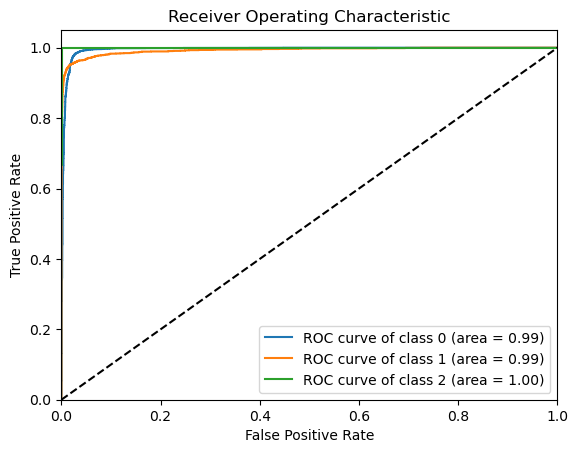

In [7]:
from sklearn.metrics import roc_auc_score, roc_curve

classes = rf.classes_
y_prob = rf.predict_proba(X_test)
fpr = {}
tpr = {}
roc_auc = {}
for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(y_test == classes[i], y_prob[:,i])
    roc_auc[i] = roc_auc_score(y_test == classes[i], y_prob[:,i])
plt.figure()
for i in range(3):
    plt.plot(fpr[i], tpr[i], label='ROC curve of class {0} (area = {1:0.2f})'.format(classes[i], roc_auc[i]))
plt.plot([0, 1], [0, 1], 'k--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.legend(loc="lower right")
plt.title('Receiver Operating Characteristic')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

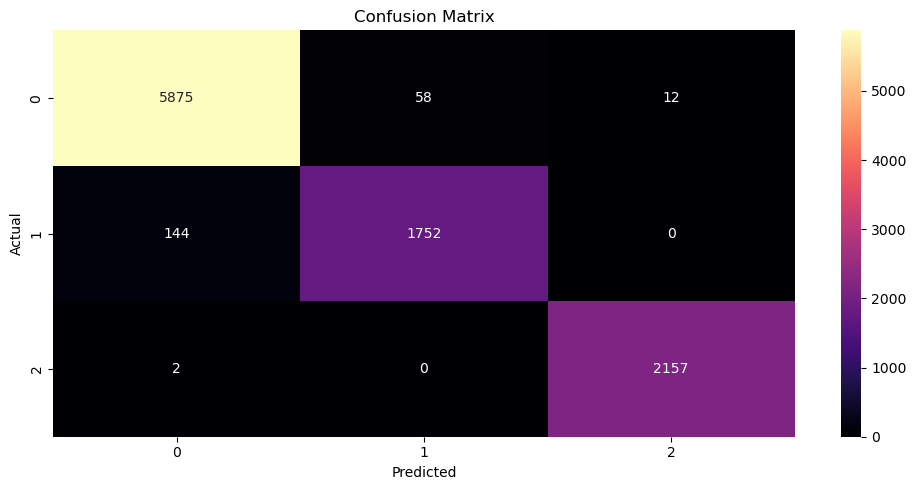

In [11]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=rf.classes_)

plt.figure(figsize=(10, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='magma', xticklabels=rf.classes_, yticklabels=rf.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.tight_layout()
plt.show()